<a href="https://colab.research.google.com/github/lakshinkhurana/SIH-eDNA/blob/ml/eDNA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install biopython

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 27.2 MB/s eta 0:00:00


In [ ]:
from Bio import SeqIO
import re
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter , defaultdict
import pandas as pd
from sklearn.preprocessing import LabelEncoder
import torch
from tensorflow.keras.preprocessing.sequence import pad_sequences
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import torch.optim as optim
from torch.utils.data import Dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
import seaborn as sns
from imblearn.over_sampling import RandomOverSampler

In [ ]:
# def extract_protein_info(header):
#     """Extract detailed information from FASTA header"""
#     info = {
#         'accession': None,
#         'protein_name': None,
#         'organism': None,
#         'gene_name': None,
#         'organism_code': None
#     }

#     # Extract accession (first part before |)
#     acc_match = re.search(r'^(\w+\|\w+\|\w+)', header)
#     if acc_match:
#         info['accession'] = acc_match.group(1)

#     # Extract protein name (text before OS=)
#     protein_match = re.search(r'^[^|]*\|[^|]*\|([^=]+?)(?:\s+OS=|$)', header)
#     if protein_match:
#         info['protein_name'] = protein_match.group(1).strip()

#     # Extract organism with OS=
#     os_match = re.search(r'OS=([^=]+?)(?:\s+OX=|$)', header)
#     if os_match:
#         info['organism'] = os_match.group(1).strip()

#     # Extract gene name with GN=
#     gn_match = re.search(r'GN=([^=]+?)(?:\s+[A-Z]{2}=|$)', header)
#     if gn_match:
#         info['gene_name'] = gn_match.group(1).strip()

#     # Also try bracket format for organism
#     if not info['organism']:
#         bracket_match = re.search(r'\[([^\]]+)\]', header)
#         if bracket_match:
#             info['organism'] = bracket_match.group(1)

#     return info

# def classify_organism_type(species_name):
#     """Basic organism type classification based on common patterns"""
#     if not species_name:
#         return 'Unknown'

#     species_lower = species_name.lower()

#     # Common bacterial indicators
#     bacteria_indicators = ['escherichia', 'bacillus', 'streptococcus', 'staphylococcus',
#                           'pseudomonas', 'salmonella', 'clostridium', 'klebsiella']

#     # Common eukaryotic indicators
#     eukaryote_indicators = ['homo', 'mus', 'rattus', 'drosophila', 'caenorhabditis',
#                            'arabidopsis', 'saccharomyces', 'schizosaccharomyces']

#     # Common archaeal indicators
#     archaea_indicators = ['methanococcus', 'thermococcus', 'pyrococcus', 'sulfolobus']

#     for indicator in bacteria_indicators:
#         if indicator in species_lower:
#             return 'Bacteria'

#     for indicator in eukaryote_indicators:
#         if indicator in species_lower:
#             return 'Eukaryota'

#     for indicator in archaea_indicators:
#         if indicator in species_lower:
#             return 'Archaea'

#     return 'Unknown'

# def fasta_to_csv(fasta_file, output_csv, min_samples=10, max_sequence_length=2000):
#     """
#     Convert FASTA file to CSV with comprehensive protein information

#     Args:
#         fasta_file: Path to FASTA file
#         output_csv: Path for output CSV
#         min_samples: Minimum sequences per species to include
#         max_sequence_length: Maximum sequence length to include
#     """

#     print("Processing FASTA file...")

#     data = []
#     sequence_counter = 0

#     # First pass: collect all data
#     for record in SeqIO.parse(fasta_file, "fasta"):
#         sequence_counter += 1
#         if sequence_counter % 10000 == 0:
#             print(f"Processed {sequence_counter} sequences...")

#         seq_str = str(record.seq)
#         header = record.description

#         # Skip very long sequences to avoid memory issues
#         if len(seq_str) > max_sequence_length:
#             continue

#         info = extract_protein_info(header)

#         species = info['organism']
#         if not species:
#             species_match = re.search(r'\\[([^\\]]+)\\]', header)
#             if species_match:
#                 species = species_match.group(1)
#             else:
#                 species = 'Unknown'


#         species = species.strip()

#         data.append({
#             'sequence_id': record.id,
#             'sequence': seq_str,
#             'species': species,
#             'sequence_length': len(seq_str),
#             'header': header,
#             'accession': info['accession'],
#             'protein_name': info['protein_name'],
#             'gene_name': info['gene_name'],
#             'organism_type': classify_organism_type(species)
#         })

#     print(f"\\nCollected {len(data)} sequences")

#     df = pd.DataFrame(data)


#     if min_samples > 1:
#         print(f"Filtering species with at least {min_samples} samples...")
#         species_counts = df['species'].value_counts()
#         valid_species = species_counts[species_counts >= min_samples].index
#         df = df[df['species'].isin(valid_species)].copy()

#         print(f"After filtering: {len(df)} sequences across {len(valid_species)} species")

#     df['gc_content'] = df['sequence'].apply(lambda x: (x.count('G') + x.count('C')) / len(x) if len(x) > 0 else 0)


#     amino_acids = 'ACDEFGHIKLMNPQRSTVWY'
#     for aa in amino_acids:
#         df[f'{aa}_count'] = df['sequence'].apply(lambda x: x.count(aa))
#         df[f'{aa}_freq'] = df[f'{aa}_count'] / df['sequence_length']


#     df['unique_aa_count'] = df['sequence'].apply(lambda x: len(set(x)))


#     print(f"Saving to {output_csv}...")
#     df.to_csv(output_csv, index=False)


#     print("\\n=== DATASET SUMMARY ===")
#     print(f"Total sequences: {len(df)}")
#     print(f"Unique species: {df['species'].nunique()}")
#     print(f"Sequence length range: {df['sequence_length'].min()} - {df['sequence_length'].max()}")
#     print(f"Average sequence length: {df['sequence_length'].mean():.1f}")

#     print("\\nTop 10 species by count:")
#     print(df['species'].value_counts().head(10))

#     print("\\nOrganism type distribution:")
#     print(df['organism_type'].value_counts())

#     return df


# if __name__ == "__main__":

#     df = fasta_to_csv(
#         fasta_file="swissprot",
#         output_csv="protein_sequences.csv",
#         min_samples=10,
#         max_sequence_length=2000
#     )

#     print("\\nConversion complete!")
#     print(f"CSV saved with {len(df)} sequences")
#     print(f"Columns: {list(df.columns)}")

In [ ]:
aa_vocab = {
    'A': 1, 'C': 2, 'D': 3, 'E': 4, 'F': 5,
    'G': 6, 'H': 7, 'I': 8, 'K': 9, 'L': 10,
    'M': 11, 'N': 12, 'P': 13, 'Q': 14, 'R': 15,
    'S': 16, 'T': 17, 'V': 18, 'W': 19, 'Y': 20
}


In [ ]:
df=pd.read_csv('new_protein_sequences.csv')

In [ ]:
UNK_TOKEN = len(aa_vocab)

def encode_sequence(seq, vocab=aa_vocab):
    """Convert protein sequence string to integer-encoded list"""
    return [vocab.get(aa, UNK_TOKEN) for aa in seq]

# Encode all sequences in df['sequence']
df['encoded_sequence'] = df['sequence'].apply(encode_sequence)

# Pad sequences to a fixed length (e.g. 2000 like you used earlier)
MAX_LEN = int(np.percentile(df['sequence_length'], 95))
X = pad_sequences(df['encoded_sequence'], maxlen=MAX_LEN, padding='post', truncating='post')

print("Shape of X (encoded + padded):", X.shape)

Shape of X (encoded + padded): (452259, 883)


In [ ]:
# Features
sequence_features = df['encoded_sequence']   # integer encoded sequences
numeric_features = df[['sequence_length', 'gc_content', 'unique_aa_count']]
target = df['organism_type']
X = sequence_features.values
X_num = numeric_features.values

# Encode labels
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(target)

# First split: train+val and test
X_seq_trainval, X_seq_test, X_num_trainval, X_num_test, y_trainval, y_test = train_test_split(
    X, X_num, y, test_size=0.2, random_state=42, stratify=y
)

# Second split: from train+val → 80% train, 20% val
X_seq_train, X_seq_val, X_num_train, X_num_val, y_train, y_val = train_test_split(
    X_seq_trainval, X_num_trainval, y_trainval, test_size=0.2, random_state=42, stratify=y_trainval
)

print("Before Oversampling:", np.bincount(y_train))

# ----- Pad sequences to MAX_LEN -----
X_seq_train_padded = pad_sequences(X_seq_train, maxlen=MAX_LEN, padding='post', truncating='post')
X_seq_val_padded   = pad_sequences(X_seq_val,   maxlen=MAX_LEN, padding='post', truncating='post')
X_seq_test_padded  = pad_sequences(X_seq_test,  maxlen=MAX_LEN, padding='post', truncating='post')

# ----- Oversample only numeric features -----
ros = RandomOverSampler(random_state=42)
X_num_bal, y_bal = ros.fit_resample(X_num_train, y_train)

# Get oversampled indices and apply them to sequences
indices = ros.sample_indices_
X_seq_bal = X_seq_train_padded[indices]

print("After Oversampling:", np.bincount(y_bal))

# Final shapes
print("Train sequence shape (balanced):", X_seq_bal.shape)
print("Train numeric shape (balanced):", X_num_bal.shape)
print("Train labels shape (balanced):", y_bal.shape)
print("Val sequence shape:", X_seq_val_padded.shape)
print("Test sequence shape:", X_seq_test_padded.shape)
print("Classes:", label_encoder.classes_)

Before Oversampling: [  3170  41464  56999 187812]
After Oversampling: [187812 187812 187812 187812]
Train sequence shape (balanced): (751248, 883)
Train numeric shape (balanced): (751248, 3)
Train labels shape (balanced): (751248,)
Val sequence shape: (72362, 883)
Test sequence shape: (90452, 883)
Classes: ['Archaea' 'Bacteria' 'Eukaryota' 'Unknown']


In [ ]:
class ProteinDataset(Dataset):
    def __init__(self, seq_data, num_data, labels):
        self.seq_data = torch.tensor(seq_data, dtype=torch.long)   # sequences as integers
        self.num_data = torch.tensor(num_data, dtype=torch.float32) # numeric features
        self.labels = torch.tensor(labels, dtype=torch.long)        # class labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return self.seq_data[idx], self.num_data[idx], self.labels[idx]

In [ ]:
class ProteinCNN(nn.Module):
    def __init__(self, vocab_size, embed_dim, num_classes, num_numeric_features):
        super().__init__()
        # Sequence branch
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.conv1 = nn.Conv1d(embed_dim, 128, kernel_size=3, padding=1)
        self.conv2 = nn.Conv1d(128, 256, kernel_size=5, padding=2)
        self.pool = nn.AdaptiveAvgPool1d(1)

        # Numeric branch
        self.numeric_fc = nn.Sequential(
            nn.Linear(num_numeric_features, 64),
            nn.ReLU(),
            nn.Dropout(0.2)
        )

        # Merge branches
        self.fc = nn.Sequential(
            nn.Linear(256 + 64, 128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, num_classes)
        )

    def forward(self, sequence, numeric_features):
        # CNN branch
        x = self.embedding(sequence)         # [batch, seq_len, embed_dim]
        x = x.transpose(1, 2)                # [batch, embed_dim, seq_len]
        x = torch.relu(self.conv1(x))
        x = torch.relu(self.conv2(x))
        x = self.pool(x).squeeze(-1)         # [batch, 256]

        # Numeric branch
        n = self.numeric_fc(numeric_features)  # [batch, 64]

        # Concatenate
        out = torch.cat([x, n], dim=1)       # [batch, 320]
        out = self.fc(out)
        return out

In [ ]:
model = ProteinCNN(vocab_size=len(aa_vocab) + 1, embed_dim=128, num_classes=len(label_encoder.classes_), num_numeric_features=numeric_features.shape[1])

In [ ]:
criterion=nn.CrossEntropyLoss()
optimizer=optim.Adam(model.parameters(), lr=0.001)

In [ ]:
batch_size = 128

train_dataset = ProteinDataset(X_seq_bal, X_num_bal, y_bal)
val_dataset   = ProteinDataset(X_seq_val_padded, X_num_val, y_val)
test_dataset  = ProteinDataset(X_seq_test_padded, X_num_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=64, shuffle=False)
test_loader  = DataLoader(test_dataset, batch_size=64, shuffle=False)


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)
print(device)

def train_epoch(model, train_loader, criterion, optimizer):
    model.train()
    total_loss = 0
    for batch_x_seq, batch_x_num, batch_y in train_loader:
        batch_x_seq, batch_x_num, batch_y = batch_x_seq.to(device), batch_x_num.to(device), batch_y.to(device)  # move both to GPU

        optimizer.zero_grad()
        outputs = model(batch_x_seq, batch_x_num)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    return total_loss / len(train_loader)

def validate(model, val_loader, criterion):
    model.eval()
    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for batch_x_seq, batch_x_num, batch_y in val_loader:
            batch_x_seq, batch_x_num, batch_y = batch_x_seq.to(device), batch_x_num.to(device), batch_y.to(device)  # move both to GPU
            outputs = model(batch_x_seq, batch_x_num)
            loss = criterion(outputs, batch_y)
            total_loss += loss.item()

            _, predicted = torch.max(outputs.data, 1)
            total += batch_y.size(0)
            correct += (predicted == batch_y).sum().item()

    accuracy = 100 * correct / total
    return total_loss / len(val_loader), accuracy

# Training loop
epochs = 50
for epoch in range(epochs):
    train_loss = train_epoch(model, train_loader, criterion, optimizer)
    val_loss, val_acc = validate(model, val_loader, criterion)

    print(f'Epoch {epoch}: Train Loss: {train_loss:.4f}, '
          f'Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%')

    # Save the model every 5 epochs
    if (epoch + 1) % 5 == 0:
        torch.save(model.state_dict(), f'protein_cnn_epoch_{epoch+1}.pth')
        print(f'Model saved after epoch {epoch+1}')

cuda
Epoch 0: Train Loss: 0.8202, Val Loss: 0.7803, Val Acc: 67.18%
Epoch 1: Train Loss: 0.7766, Val Loss: 0.7319, Val Acc: 68.19%
Epoch 2: Train Loss: 0.7377, Val Loss: 0.7271, Val Acc: 67.89%
Epoch 3: Train Loss: 0.7050, Val Loss: 0.6735, Val Acc: 69.81%
Epoch 4: Train Loss: 0.6702, Val Loss: 0.6448, Val Acc: 71.33%
Model saved after epoch 5
Epoch 5: Train Loss: 0.6329, Val Loss: 0.6209, Val Acc: 72.51%
Epoch 6: Train Loss: 0.6005, Val Loss: 0.6015, Val Acc: 73.49%
Epoch 7: Train Loss: 0.5714, Val Loss: 0.6108, Val Acc: 73.28%
Epoch 8: Train Loss: 0.5476, Val Loss: 0.5978, Val Acc: 74.38%
Epoch 9: Train Loss: 0.5260, Val Loss: 0.6022, Val Acc: 73.83%
Model saved after epoch 10
Epoch 10: Train Loss: 0.5072, Val Loss: 0.6143, Val Acc: 74.72%
Epoch 11: Train Loss: 0.4894, Val Loss: 0.6082, Val Acc: 74.70%
Epoch 12: Train Loss: 0.4759, Val Loss: 0.6550, Val Acc: 73.97%
Epoch 13: Train Loss: 0.4607, Val Loss: 0.6756, Val Acc: 74.41%
Epoch 14: Train Loss: 0.4474, Val Loss: 0.6245, Val Acc:

KeyboardInterrupt: 

In [ ]:
model = ProteinCNN(vocab_size=len(aa_vocab) + 1, embed_dim=128, num_classes=len(label_encoder.classes_), num_numeric_features=numeric_features.shape[1])
model.load_state_dict(torch.load("protein_cnn_epoch_10.pth"))
model.to(device)
model.eval()

ProteinCNN(
  (embedding): Embedding(21, 128)
  (conv1): Conv1d(128, 128, kernel_size=(3,), stride=(1,), padding=(1,))
  (conv2): Conv1d(128, 256, kernel_size=(5,), stride=(1,), padding=(2,))
  (pool): AdaptiveAvgPool1d(output_size=1)
  (numeric_fc): Sequential(
    (0): Linear(in_features=3, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
  )
  (fc): Sequential(
    (0): Linear(in_features=320, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.5, inplace=False)
    (3): Linear(in_features=128, out_features=4, bias=True)
  )
)

Validation Accuracy: 73.83%

Classification Report:

              precision    recall  f1-score   support

           0     0.6161    0.1641    0.2592       792
           1     0.7212    0.4846    0.5797     10366
           2     0.5896    0.7253    0.6504     14250
           3     0.7961    0.8079    0.8020     46954

    accuracy                         0.7383     72362
   macro avg     0.6807    0.5455    0.5728     72362
weighted avg     0.7427    0.7383    0.7343     72362



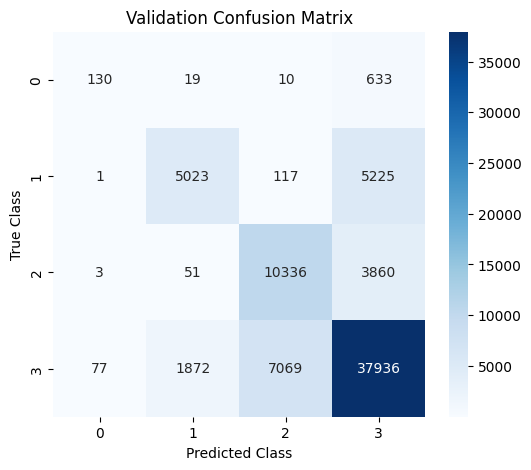

In [ ]:
all_preds = []
all_targets = []

with torch.no_grad():
    for seq, num, labels in val_loader:
        seq, num, labels = seq.to(device), num.to(device), labels.to(device)
        outputs = model(seq, num)
        preds = outputs.argmax(dim=1)
        all_preds.append(preds.cpu().numpy())
        all_targets.append(labels.cpu().numpy())

all_preds = np.concatenate(all_preds)
all_targets = np.concatenate(all_targets)

# --- 3️⃣ Compute metrics ---
acc = accuracy_score(all_targets, all_preds)
print(f"Validation Accuracy: {acc*100:.2f}%\n")

print("Classification Report:\n")
print(classification_report(all_targets, all_preds, digits=4, zero_division=0))

cm = confusion_matrix(all_targets, all_preds)

# --- 4️⃣ Visualize confusion matrix ---
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("Validation Confusion Matrix")
plt.show()